# Умный дом: предиктивное управление освещением на кухне

**Задача.** По данным сенсоров умного дома (движение, мощность, температура, влажность, двери, приборы) научиться
управлять светом на кухне проактивно, то есть включать его до того, как человек нажмёт выключатель.

**Что в этом ноутбуке:**
1. EDA: что на самом деле происходит в данных.
2. Предобработка: аномалии и пропуски, без заглядывания в будущее.
3. **Эксперимент 1.** Исходная постановка (классификация состояния света в текущую секунду) и почему метрика ~0.999 в ней мало что значит.
4. **Эксперимент 2.** Честный прогноз: включится ли свет в ближайшие 60 секунд? Валидация по времени, сравнение с бейзлайнами, метрики на уровне событий.

Данные: 8 дней показаний с частотой 1 Гц (~700 тыс. строк), 14 столбцов. Целевая переменная — `Light_Kitchen`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font_scale=1.0)
RANDOM_STATE = 42

In [2]:
DATA_PATH = "train_data.csv"   # в Colab/Kaggle укажите свой путь к файлу

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"]).set_index("timestamp")
print(f"Размер: {df.shape}")
print(f"Период: {df.index.min()} — {df.index.max()}")
df.head()

Размер: (698976, 14)
Период: 2025-03-03 00:00:00 — 2025-03-11 02:09:35.898888758


,TimeOfDay,month,Movement_Living,Movement_Kitchen,Movement_Hallway,FrontDoor_Open,Light_Living,Light_Kitchen,Kettle_On,Heater_State,Window_State,Power,Temperature,Humidity
timestamp,,,,,,,,,,,,,,
2025-03-03 00:00:00.000000000,3,3,0.0,0.0,0,0,0,0,0,0,0,0.1413,NaN,36.1
2025-03-03 00:00:01.000001286,3,3,0.0,0.0,0,0,0,0,0,0,0,0.1427,17.8,36.2
2025-03-03 00:00:02.000002572,3,3,0.0,0.0,0,0,0,0,0,0,0,0.1651,18.2,36.5
2025-03-03 00:00:03.000003858,3,3,0.0,0.0,0,0,0,0,0,0,0,0.1530,18.0,36.9
2025-03-03 00:00:04.000005144,3,3,0.0,NaN,0,0,0,0,0,0,0,0.1714,17.9,37.3


## 1. EDA

In [3]:
print("Пропуски по столбцам:")
print(df.isna().sum()[lambda s: s > 0])
print()
print("Доля времени, когда свет на кухне включён:", round(df["Light_Kitchen"].mean(), 3))

Пропуски по столбцам:
Movement_Living     34983
Movement_Kitchen    34954
Temperature         34261
Humidity            34131
dtype: int64

Доля времени, когда свет на кухне включён: 0.224


### Ключевое наблюдение: свет переключается редко
Посмотрим не на отдельные секунды, а на **события**: сколько раз свет включался и как долго горел.

In [4]:
y = df["Light_Kitchen"]
segments = (y.diff() != 0).cumsum()
seg = df.groupby(segments).agg(state=("Light_Kitchen", "first"), seconds=("Light_Kitchen", "size"))

n_on = int((y.diff() == 1).sum())
print(f"Включений света за весь период: {n_on}")
print(f"Медианная длительность «свет горит»:    {seg.loc[seg.state == 1, 'seconds'].median() / 60:.0f} мин")
print(f"Медианная длительность «свет выключен»: {seg.loc[seg.state == 0, 'seconds'].median() / 60:.0f} мин")
print()
for h in [1, 60, 300]:
    print(f"Состояние через {h:>3} с совпадает с текущим в {(y == y.shift(-h)).mean():.2%} случаев")

Включений света за весь период: 72
Медианная длительность «свет горит»:    26 мин
Медианная длительность «свет выключен»: 34 мин

Состояние через   1 с совпадает с текущим в 99.98% случаев
Состояние через  60 с совпадает с текущим в 98.76% случаев
Состояние через 300 с совпадает с текущим в 94.04% случаев


**Вывод:** за 8 дней всего ~70 включений. Состояние света крайне инерционно: даже наивное правило
«через минуту будет так же, как сейчас» угадывает почти 99% секунд. Поэтому посекундная метрика (accuracy, ROC-AUC)
почти полностью определяется длинными стабильными участками, а **интересные моменты, то есть включения, составляют меньше 1% данных.**

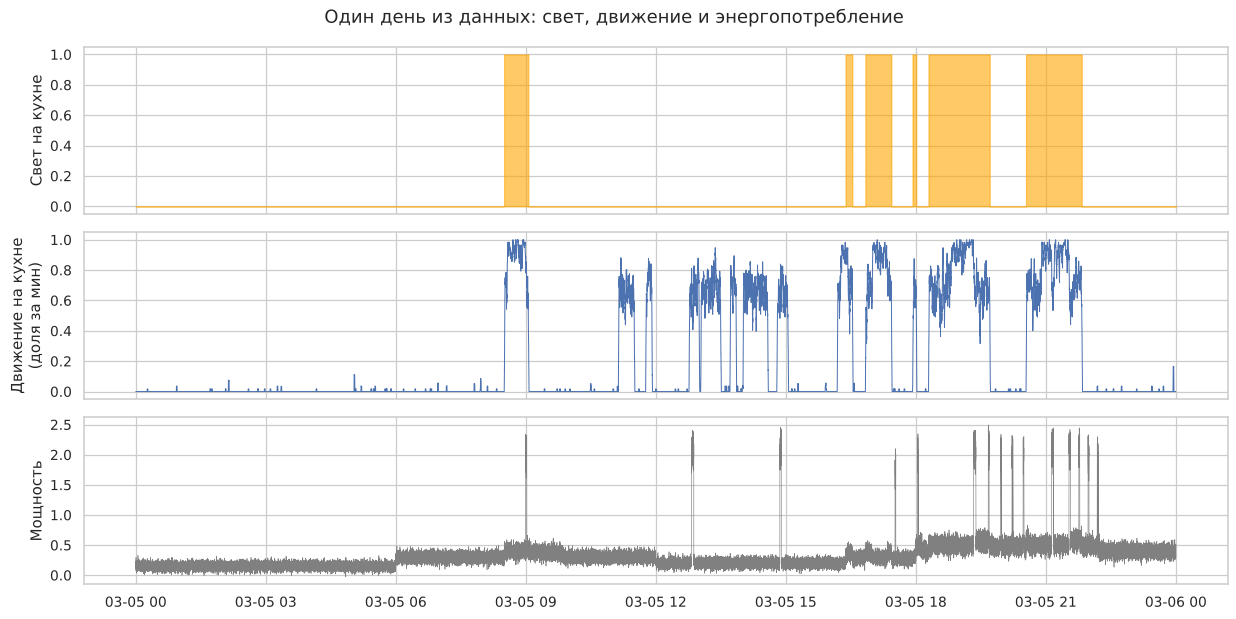

In [5]:
day = df.loc["2025-03-05"]
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
axes[0].fill_between(day.index, day["Light_Kitchen"], step="post", alpha=0.6, color="orange")
axes[0].set_ylabel("Свет на кухне")
axes[1].plot(day.index, day["Movement_Kitchen"].rolling(60, min_periods=1).mean(), lw=0.8)
axes[1].set_ylabel("Движение на кухне\n(доля за мин)")
axes[2].plot(day.index, day["Power"], lw=0.5, color="gray")
axes[2].set_ylabel("Мощность")
fig.suptitle("Один день из данных: свет, движение и энергопотребление")
plt.tight_layout()
plt.show()

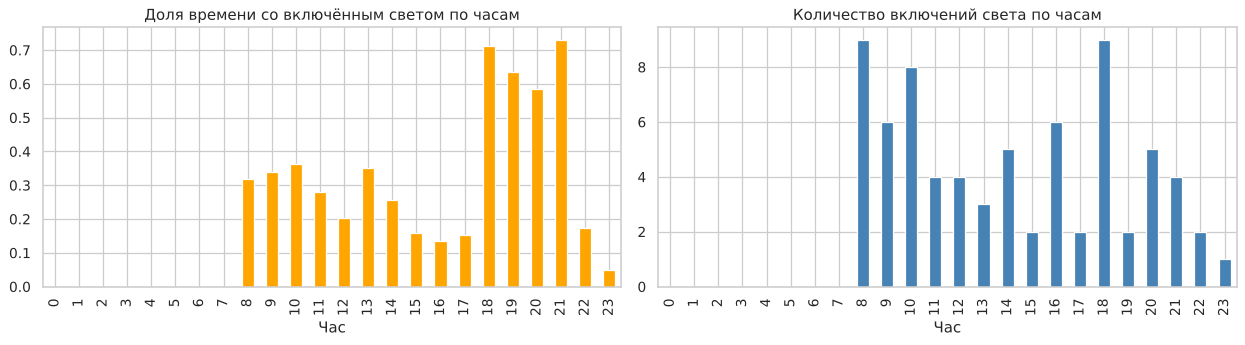

In [6]:
hourly = df.groupby(df.index.hour)["Light_Kitchen"].mean()
on_events = df.index[(y.diff() == 1)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hourly.plot(kind="bar", ax=axes[0], color="orange")
axes[0].set_title("Доля времени со включённым светом по часам")
axes[0].set_xlabel("Час")
pd.Series(on_events.hour).value_counts().reindex(range(24), fill_value=0).plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Количество включений света по часам")
axes[1].set_xlabel("Час")
plt.tight_layout()
plt.show()

## 2. Предобработка

**Аномалии.** В температуре и влажности есть явные «заглушки» сбоя датчика: −10 °C и 40 °C, влажность −5% и 110%.
Метод IQR здесь не подходит: на мощности он вырезал бы **реальные** включения приборов (чайник даёт ~2 кВт),
а на влажности задел бы нормальные значения ~59%. Поэтому используем физические границы.

**Пропуски.** Заполняем **только по прошлым данным**, иначе в прогнозе появится утечка из будущего:
- непрерывные величины: экспоненциальное скользящее среднее по прошлым значениям (EMA);
- дискретные датчики: протягиваем последнее известное состояние (forward fill).

In [7]:
for col in ["Temperature", "Humidity", "Power"]:
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    n_iqr = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    print(f"{col:<12} min={s.min():>6.1f}  max={s.max():>6.1f}  выбросов по IQR: {n_iqr}")

Temperature  min= -10.0  max=  40.0  выбросов по IQR: 14036
Humidity     min=  -5.0  max= 110.0  выбросов по IQR: 17505
Power        min=  -0.1  max=   4.4  выбросов по IQR: 10489


In [8]:
def clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    # физически невозможные значения -> пропуск
    df.loc[(df["Temperature"] <= -5) | (df["Temperature"] >= 40), "Temperature"] = np.nan
    df.loc[(df["Humidity"] < 0) | (df["Humidity"] > 100), "Humidity"] = np.nan

    # непрерывные: EMA только по прошлому (ignore_na -> значение в точке пропуска = среднее по предыдущим)
    for col in ["Temperature", "Humidity", "Power"]:
        ema = df[col].ewm(span=60, ignore_na=True).mean()
        df[col] = df[col].fillna(ema)

    # дискретные: последнее известное состояние
    discrete = ["Movement_Living", "Movement_Kitchen", "Movement_Hallway", "FrontDoor_Open",
                "Light_Living", "Kettle_On", "Heater_State", "Window_State"]
    df[discrete] = df[discrete].ffill().fillna(0)
    return df

data = clean(df)
print("Пропусков после очистки:", int(data.isna().sum().sum()))

Пропусков после очистки: 1


## 3. Эксперимент 1: исходная постановка (состояние света «сейчас»)

Воспроизводим исходную задачу: по показаниям в момент *t* определить `Light_Kitchen` в тот же момент *t*.
Признаки: текущие значения датчиков, лаги, скользящие статистики, время суток. Валидация: первые 80% по времени — обучение, последние 20% — тест.

In [9]:
SENSORS = ["Movement_Kitchen", "Movement_Living", "Movement_Hallway", "Power", "Temperature", "Humidity",
           "Light_Living", "Kettle_On", "Heater_State", "Window_State", "FrontDoor_Open"]

def build_features(d: pd.DataFrame) -> pd.DataFrame:
    """Признаки только по данным в момент t и раньше."""
    X = d[SENSORS].copy()
    X["hour"] = d.index.hour
    X["is_weekend"] = (d.index.dayofweek >= 5).astype(int)

    for col in ["Movement_Kitchen", "Movement_Living", "Power"]:
        for lag in [5, 30, 60, 300]:
            X[f"{col}_lag_{lag}"] = d[col].shift(lag)

    for col in ["Movement_Kitchen", "Movement_Living", "Movement_Hallway"]:
        for w in [10, 60, 300]:
            X[f"{col}_sum_{w}"] = d[col].rolling(w, min_periods=1).sum()

    for w in [10, 60, 300]:
        X[f"Power_mean_{w}"] = d["Power"].rolling(w, min_periods=1).mean()
        X[f"Power_std_{w}"] = d["Power"].rolling(w, min_periods=1).std()

    # сколько секунд прошло с последнего движения в гостиной / на кухне / в коридоре
    t = pd.Series(np.arange(len(d)), index=d.index, dtype=float)
    for col in ["Movement_Kitchen", "Movement_Living", "Movement_Hallway"]:
        last = t.where(d[col] > 0).ffill()
        X[f"sec_since_{col}"] = (t - last).fillna(1e5).clip(upper=1e5)
    return X

X_all = build_features(data)
y_all = data["Light_Kitchen"]
print("Число признаков:", X_all.shape[1])

Число признаков: 43


In [10]:
split = int(len(X_all) * 0.8)
X_tr, X_te = X_all.iloc[300:split], X_all.iloc[split:]
y_tr, y_te = y_all.iloc[300:split], y_all.iloc[split:]

def fit_models(X_tr, y_tr):
    logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                        class_weight="balanced", random_state=RANDOM_STATE)
    logreg.fit(X_tr, y_tr)
    gb.fit(X_tr, y_tr)
    return {"LogReg": logreg, "GradBoost": gb}

models_1 = fit_models(X_tr, y_tr)
rows = []
# простейший бейзлайн из одного признака: было ли движение на кухне за последние 5 минут
rows.append({"Модель": "Правило: движение на кухне за 5 мин",
             "ROC-AUC": roc_auc_score(y_te, X_te["Movement_Kitchen_sum_300"]),
             "F1": f1_score(y_te, (X_te["Movement_Kitchen_sum_300"] > 0).astype(int))})
for name, m in models_1.items():
    p = m.predict_proba(X_te)[:, 1]
    rows.append({"Модель": name, "ROC-AUC": roc_auc_score(y_te, p), "F1": f1_score(y_te, (p > 0.5).astype(int))})
exp1 = pd.DataFrame(rows).set_index("Модель").round(3)
exp1

,ROC-AUC,F1
Модель,,
Правило: движение на кухне за 5 мин,0.988,0.764
LogReg,0.997,0.964
GradBoost,1.000,0.994


**Вывод по эксперименту 1.** Модели действительно дают ROC-AUC около 0.99, но и **правило из одного признака**
(«было ли движение на кухне за последние 5 минут») уже даёт сопоставимое качество. В такой постановке модель
по сути **распознаёт, что человек уже на кухне и свет уже горит**, а не предсказывает. Для проактивного управления
такая модель бесполезна: к моменту, когда она «узнаёт», свет уже включили руками.

Значит, задачу нужно переформулировать.

## 4. Эксперимент 2: можно ли предсказать включение света заранее?

**Постановка.** В момент *t*, когда свет на кухне **выключен**, предсказываем, включится ли он в течение следующих **H секунд**.
- Используем только данные до момента *t* включительно.
- Объекты — только секунды, когда свет выключен.
- Классы сильно несбалансированы, поэтому основная метрика — **PR-AUC**. У случайной модели она равна доле положительных,
  поэтому дополнительно считаем **lift** = PR-AUC / доля положительных (во сколько раз лучше случайного угадывания).
- Валидация — **TimeSeriesSplit** (4 фолда, окно обучения расширяется).

К признакам добавляем «распорядок»: минуту дня и время с последнего выключения света (оно известно системе в момент *t*).

### 4.1. Что происходит с датчиками вокруг момента включения
Прежде чем строить модель, проверим, есть ли у включения **предвестники**: например, движение в коридоре или гостиной незадолго до этого.

Медианная задержка между включением света и первым движением на кухне: 1 с


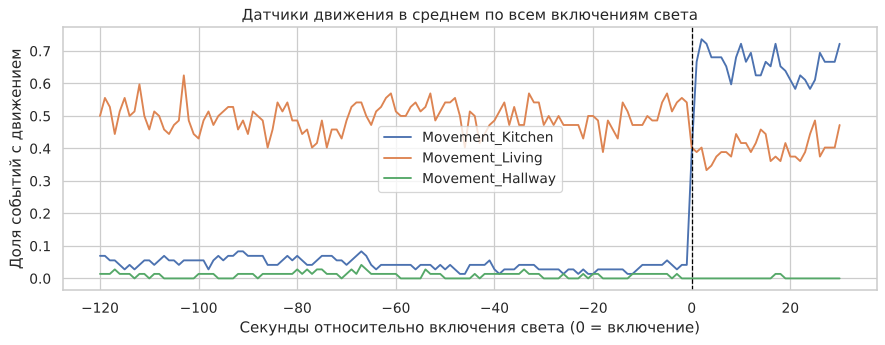

In [11]:
on_idx = np.where(np.diff(y_all.values) == 1)[0] + 1
offsets = np.arange(-120, 31)
profile = pd.DataFrame({
    col: [data[col].values[on_idx + o].mean() for o in offsets]
    for col in ["Movement_Kitchen", "Movement_Living", "Movement_Hallway"]
}, index=offsets)

fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax)
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_xlabel("Секунды относительно включения света (0 = включение)")
ax.set_ylabel("Доля событий с движением")
ax.set_title("Датчики движения в среднем по всем включениям света")
plt.tight_layout()
plt.show()

first_move = [int(np.argmax(data["Movement_Kitchen"].values[i:i + 600] > 0)) for i in on_idx]
print(f"Медианная задержка между включением света и первым движением на кухне: {np.median(first_move):.0f} с")

**Важный вывод.** Движение на кухне появляется **одновременно со светом**, а движение в гостиной и коридоре
перед включением не отличается от обычного фона. Значит, **в данных нет краткосрочных предвестников включения**:
предсказать его за минуту нельзя никакой моделью. Это ограничение данных, а не алгоритма.

Тогда остаётся проверить, можно ли предсказать включение на более длинном горизонте по **распорядку дня** жильцов.

In [12]:
def build_forecast_features(d: pd.DataFrame) -> pd.DataFrame:
    X = build_features(d)
    X["minute_of_day"] = d.index.hour * 60 + d.index.minute
    t = pd.Series(np.arange(len(d)), index=d.index, dtype=float)
    light_off_moment = t.where(d["Light_Kitchen"].diff() == -1).ffill()
    X["sec_since_light_off"] = (t - light_off_moment).fillna(1e5)
    return X

X_fc = build_forecast_features(data)

def make_target(y: pd.Series, H: int):
    future_on = y[::-1].rolling(H, min_periods=1).max()[::-1].shift(-1)  # включится ли в (t, t+H]
    mask = (y == 0) & future_on.notna()
    mask.iloc[:300] = False
    return mask, future_on

def gb_model():
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=31,
                                          class_weight="balanced", random_state=RANDOM_STATE)

tscv = TimeSeriesSplit(n_splits=4)
rows = []
for H in [60, 300, 900, 1800]:
    mask, future_on = make_target(y_all, H)
    X, yH = X_fc[mask], future_on[mask].astype(int)
    for fold, (tr, te) in enumerate(tscv.split(X), 1):
        Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], yH.iloc[tr], yH.iloc[te]
        # бейзлайн «по расписанию»: частота включений в этот час дня на обучающей части
        hour_rate = ytr.groupby(Xtr["hour"]).mean()
        p_sched = Xte["hour"].map(hour_rate).fillna(ytr.mean())
        p_gb = gb_model().fit(Xtr, ytr).predict_proba(Xte)[:, 1]
        for name, p in [("Расписание (частота по часам)", p_sched), ("GradBoost", p_gb)]:
            ap = average_precision_score(yte, p)
            rows.append({"H, мин": H // 60, "fold": fold, "Модель": name, "PR-AUC": ap,
                         "ROC-AUC": roc_auc_score(yte, p), "Доля полож.": yte.mean(), "Lift": ap / yte.mean()})

hor = pd.DataFrame(rows)
summary = (hor.groupby(["H, мин", "Модель"])[["Доля полож.", "PR-AUC", "ROC-AUC", "Lift"]]
              .mean().round(3).unstack("Модель"))
summary

Доля полож.                                  PR-AUC  \
Модель   GradBoost Расписание (частота по часам) GradBoost   
H, мин                                                       
1            0.009                         0.009     0.030   
5            0.042                         0.042     0.140   
15           0.116                         0.116     0.344   
30           0.203                         0.203     0.573   

                                       ROC-AUC                                \
Модель Расписание (частота по часам) GradBoost Расписание (частота по часам)   
H, мин                                                                         
1                              0.023     0.725                         0.725   
5                              0.120     0.773                         0.738   
15                             0.336     0.830                         0.761   
30                             0.518     0.859                         0.804   

            Lift                                
Модель GradBoost Расписание (частота по часам)  
H, мин                                          
1          4.165                         3.049  
5          4.185                         3.400  
15         3.333                         3.604  
30         3.161                         2.874

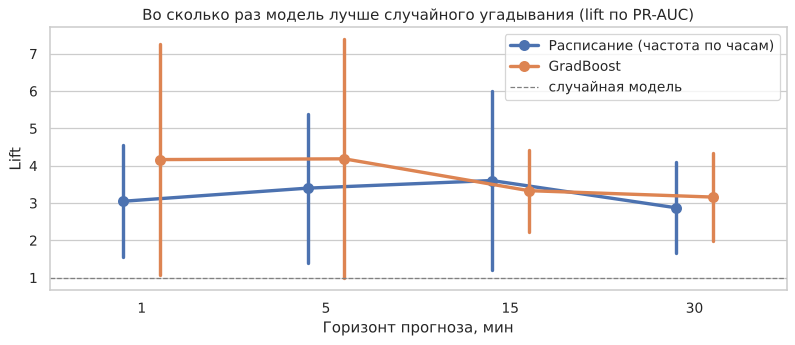

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.pointplot(data=hor, x="H, мин", y="Lift", hue="Модель", errorbar="sd", dodge=0.2, ax=ax)
ax.axhline(1, color="gray", ls="--", lw=1, label="случайная модель")
ax.set_title("Во сколько раз модель лучше случайного угадывания (lift по PR-AUC)")
ax.set_xlabel("Горизонт прогноза, мин")
ax.legend()
plt.tight_layout()
plt.show()

**Как читать результат:**
- на горизонте **1 минута** абсолютное качество очень низкое (PR-AUC ≈ 0.03): из 100 срабатываний ~97 были бы ложными.
  Lift выше 1 только потому, что включения чаще случаются в определённые часы. Для управления светом это бесполезно;
- на горизонте **15–30 минут** прогноз становится содержательным: PR-AUC 0.34–0.57;
- **бейзлайн «по расписанию» почти так же хорош, как бустинг по PR-AUC.** Основная предсказуемость в этих данных —
  это распорядок дня. Бустинг выигрывает в ранжировании (ROC-AUC) и в стабильности между периодами (см. ниже).

### 4.2. Основная модель: прогноз на 15 минут
Сравним логистическую регрессию и градиентный бустинг и посмотрим, на какие признаки опирается модель.

In [14]:
H = 900
mask, future_on = make_target(y_all, H)
X15, y15 = X_fc[mask], future_on[mask].astype(int)

res15 = []
for fold, (tr, te) in enumerate(tscv.split(X15), 1):
    Xtr, Xte, ytr, yte = X15.iloc[tr], X15.iloc[te], y15.iloc[tr], y15.iloc[te]
    logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    hour_rate = ytr.groupby(Xtr["hour"]).mean()
    preds = {
        "Расписание (частота по часам)": Xte["hour"].map(hour_rate).fillna(ytr.mean()),
        "LogReg": logreg.fit(Xtr, ytr).predict_proba(Xte)[:, 1],
        "GradBoost": gb_model().fit(Xtr, ytr).predict_proba(Xte)[:, 1],
    }
    for name, p in preds.items():
        res15.append({"fold": fold, "Модель": name, "PR-AUC": average_precision_score(yte, p),
                      "ROC-AUC": roc_auc_score(yte, p)})

res15 = pd.DataFrame(res15)
print(f"Доля положительных: {y15.mean():.3f}")
res15.groupby("Модель")[["PR-AUC", "ROC-AUC"]].agg(["mean", "std"]).round(3).sort_values(("PR-AUC", "mean"))

Доля положительных: 0.106


PR-AUC        ROC-AUC       
                                mean    std    mean    std
Модель                                                    
LogReg                         0.218  0.076   0.723  0.069
Расписание (частота по часам)  0.336  0.110   0.761  0.131
GradBoost                      0.344  0.042   0.830  0.033

**Результат на горизонте 15 минут:**
- бустинг и бейзлайн «по расписанию» дают сопоставимый PR-AUC (≈0.34 при доле положительных ≈0.11, то есть в ~3 раза лучше случайного);
- бустинг заметно лучше по **ROC-AUC** (0.83 против 0.76) и в **2–3 раза стабильнее между фолдами**:
  расписание по часам «ломается» в дни с нетипичным распорядком, а модель дополнительно учитывает,
  сколько прошло с последнего выключения света и активность в доме;
- логистическая регрессия хуже обоих: зависимость от времени суток нелинейная, а час дня для неё — просто число.

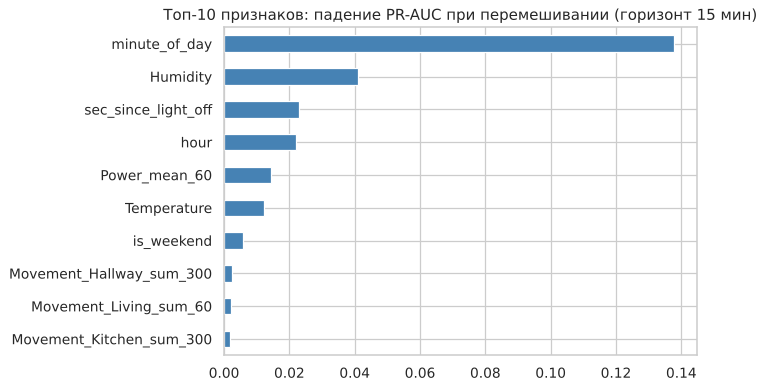

In [15]:
tr, te = list(tscv.split(X15))[-1]
gb15 = gb_model().fit(X15.iloc[tr], y15.iloc[tr])
Xs = X15.iloc[te].sample(40000, random_state=RANDOM_STATE)
ys = y15.loc[Xs.index]
pi = permutation_importance(gb15, Xs, ys, scoring="average_precision", n_repeats=3,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xs.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
imp[::-1].plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Топ-10 признаков: падение PR-AUC при перемешивании (горизонт 15 мин)")
plt.tight_layout()
plt.show()

**Что видно по важности признаков:** главный признак — минута дня, то есть распорядок. Дальше идут время с последнего выключения света и «косвенные часы»: влажность и температура в этих данных меняются в течение суток, поэтому модель частично использует их как индикатор времени. На реальных данных это стоит проверить отдельно: такая зависимость может не перенестись на другой дом или сезон.

## 5. Итоги

1. **Исходная постановка** (состояние света в текущую секунду) даёт ROC-AUC ≈ 0.99–1.0, но почти тот же результат
   даёт правило из одного признака. Модель распознаёт текущую ситуацию, а не прогнозирует её.
2. **Анализ событий** показал, что движение на кухне появляется одновременно со светом (медианная задержка 1 с),
   а других предвестников нет. Поэтому предсказать включение за минуту практически невозможно (PR-AUC ≈ 0.03).
3. **Основной источник предсказуемости — распорядок дня.** На горизонте 15 минут простой бейзлайн «частота по часам»
   и градиентный бустинг дают сопоставимый PR-AUC (~0.34, в ~3 раза лучше случайного); бустинг выигрывает
   по ROC-AUC (0.83 против 0.76) и устойчивости между периодами.
4. **Практическая рекомендация:** свет включать реактивно по датчику движения (задержка ~1 с незаметна),
   а прогноз на 15–30 минут использовать для сценариев, где нужна подготовка заранее
   (режимы энергопотребления, климат, «сценарий утро»).

**Ограничения:** 8 дней данных и ~70 включений, поэтому оценки шумные (см. разброс по фолдам).
Данные, судя по всему, синтетические. На реальных данных стоит заново проверить предвестники:
там они могут быть (например, движение в коридоре перед заходом на кухню).